Dataset Overview

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 60)

pct = pd.read_csv("../data/mineral_percentages.csv")
raw = pd.read_csv("../data/raw_holes.csv")
tsa = pd.read_csv("../data/tsa_comparison.csv")

print(f"Depth intervals: {len(pct)}")
print(f"Unique holes: {pct['hole_id'].nunique()}")
print(f"Raw readings: {len(raw)}")
print(f"TSA comparison rows: {len(tsa)}")

pct.head()

Depth intervals: 276
Unique holes: 20
Raw readings: 1073
TSA comparison rows: 65


,hole_id,depth,AMPHIBOLE,CARBONATE,CHLORITE,DARK-MICA,EPIDOTE,KAOLIN,OTHER-ALOH,OTHER-MGOH,SERPENTINE,SMECTITE,SULPHATE,TOURMALINE,WHITE-MICA,total_n
0,05GJD001,150.0,0.00,9.63,56.72,23.07,0.0,2.14,0.0,0.0,0.0,0.0,0.00,0.0,8.44,841
1,05GJD001,170.0,31.46,27.67,23.75,7.65,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,9.47,1478
2,05GJD001,190.0,8.35,5.13,73.10,9.62,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,3.80,1736
3,05GJD001,210.0,0.00,3.77,69.05,16.48,0.0,0.00,2.3,0.0,0.0,0.0,0.00,0.0,8.41,2045
4,05GJD001,230.0,0.00,32.60,16.52,0.00,0.0,0.00,20.1,0.0,0.0,0.0,10.49,0.0,20.28,1144


Interpretation:
The dataset includes information from 20 drill holes, with 276 processed depth intervals and 1,073 raw mineral readings. There are also 65 records available for comparing the TSA classification methods. This gives enough data to carry out an initial exploratory analysis and understand the main mineral patterns in the selected holes.

Baseline Classifier Results

In [22]:
MIN_SCAN_COUNT = 20
WHITE_MICA_ALTERED = 40
CHLORITE_ALTERED = 25
HEMATITE_ORE = 15
CHLORITE_ORE = 15
WASTE_COMBINED = 55
WHITE_MICA_WASTE_MAX = 15


def classify_interval(row):

    total = row.get("total_n", 0)

    # Rule 4 - insufficient scan support
    if total < MIN_SCAN_COUNT:
        return "Unclassified"

    wm = row.get("WHITE-MICA", 0)
    ch = row.get("CHLORITE", 0)
    he = row.get("HEMATITE", 0)
    ka = row.get("KAOLIN", 0)
    go = row.get("GOETHITE", 0)

    # Rule 1 - altered zone
    if wm >= WHITE_MICA_ALTERED and ch >= CHLORITE_ALTERED:
        return "Altered zone"

    # Rule 2 - possible ore zone
    if he >= HEMATITE_ORE and ch >= CHLORITE_ORE:
        return "Possible ore zone"

    # Rule 3 - waste rock
    if (ka + go) >= WASTE_COMBINED and wm < WHITE_MICA_WASTE_MAX:
        return "Waste rock"

    # Rule 5 - no rule matched
    return "Unclassified"


# Apply classifier
pct["classifier_label"] = pct.apply(
    classify_interval,
    axis=1
)

# Count results
counts = pct["classifier_label"].value_counts()

total_intervals = len(pct)
unclassified_count = counts.get("Unclassified", 0)

unclassified_rate = (
    unclassified_count / total_intervals * 100
)

print("=" * 55)
print("BASELINE CLASSIFIER RESULTS")
print("=" * 55)

for label in [
    "Possible ore zone",
    "Altered zone",
    "Waste rock",
    "Unclassified"
]:
    n = counts.get(label, 0)
    percentage = n / total_intervals * 100

    print(
        f"{label:22s}: "
        f"{n:3d} ({percentage:.1f}%)"
    )

print("-" * 55)

print(f"Total intervals: {total_intervals}")

print(
    f"UNCLASSIFIED RATE: "
    f"{unclassified_rate:.1f}%"
)

print("=" * 55)

BASELINE CLASSIFIER RESULTS
Possible ore zone     :   0 (0.0%)
Altered zone          :   6 (2.2%)
Waste rock            :   0 (0.0%)
Unclassified          : 270 (97.8%)
-------------------------------------------------------
Total intervals: 276
UNCLASSIFIED RATE: 97.8%


Interpretation:
The baseline classifier was applied to all 276 processed depth intervals. Only 6 intervals, or 2.2%, were classified as altered zones. No intervals were classified as possible ore zones or waste rock, while 270 intervals remained unclassified. This gives an unclassified rate of 97.8%. The high unclassified rate shows that the current placeholder classifier thresholds do not match the mineral composition of this dataset well. The absence of hematite and goethite, together with the low occurrence of kaolin, is also likely to limit the classifier. These results show that the rules need to be reviewed with geological expert input.

Raw Data Quality Check

In [4]:
NO_DATA = -3.402823e+38

total = len(raw)
sentinel = (raw["count"] == NO_DATA).sum()
zeros = (raw["count"] == 0).sum()
nulls = raw["count"].isna().sum()

usable = total - sentinel - zeros - nulls

print("DATA QUALITY SUMMARY")
print("=" * 45)
print(f"Total raw readings: {total}")
print(f"No-data sentinel: {sentinel} ({sentinel/total*100:.1f}%)")
print(f"Zero counts: {zeros} ({zeros/total*100:.1f}%)")
print(f"Null values: {nulls} ({nulls/total*100:.1f}%)")
print(f"Usable readings: {usable} ({usable/total*100:.1f}%)")

DATA QUALITY SUMMARY
Total raw readings: 1073
No-data sentinel: 0 (0.0%)
Zero counts: 0 (0.0%)
Null values: 0 (0.0%)
Usable readings: 1073 (100.0%)


Interpretation:
The raw data was checked for missing values, zero counts and no-data sentinel values. No invalid readings were found in the current sample, which means 100% of the 1,073 raw readings were usable for this analysis. This suggests the extracted data is clean, although this result only applies to the current sample and not necessarily the entire HyLogger dataset.

In [5]:
print(tsa.columns.tolist())
tsa.head()

['hole_id', 'depth', 'sTSAS', 'uTSAS', 'agreement']


,hole_id,depth,sTSAS,uTSAS,agreement
0,05GJD001,150.0,CHLORITE,CHLORITE,all_agree
1,05GJD001,170.0,AMPHIBOLE,AMPHIBOLE,all_agree
2,05GJD001,190.0,CHLORITE,CHLORITE,all_agree
3,05GJD001,210.0,CHLORITE,CHLORITE,all_agree
4,05GJD001,230.0,CARBONATE,CARBONATE,all_agree


TSA Method Agreement

In [6]:
print("TSA METHOD AGREEMENT SUMMARY")
print("=" * 45)

agreement_counts = tsa["agreement"].value_counts()
print(agreement_counts)

agreement_pct = tsa["agreement"].value_counts(normalize=True) * 100

print("\nAgreement percentages:")
print(agreement_pct.round(1))

TSA METHOD AGREEMENT SUMMARY
agreement
all_agree    65
Name: count, dtype: int64

Agreement percentages:
agreement
all_agree    100.0
Name: proportion, dtype: float64


Interpretation:
The sTSAS and uTSAS classifications were compared across 65 available records. All 65 records produced the same dominant mineral result, giving an agreement rate of 100%. This shows strong consistency between these two TSA methods for the current sample.

In [7]:
print(raw.columns.tolist())
raw.head()

['hole_id', 'depth', 'value', 'count']


,hole_id,depth,value,count
0,05GJD001,150.0,CHLORITE,477
1,05GJD001,150.0,DARK-MICA,194
2,05GJD001,150.0,CARBONATE,81
3,05GJD001,150.0,WHITE-MICA,71
4,05GJD001,150.0,KAOLIN,18


Interpretation:
Wt1 confidence values could not be analysed because they are not included in the current raw_holes.csv file. The available raw data contains hole ID, depth, mineral value and count, but no Wt1 field. This means the percentage of Wt1 values equal to 1.0 cannot be calculated with the current ETL output and should be reported as a data limitation.i

Mineral Composition with Depth

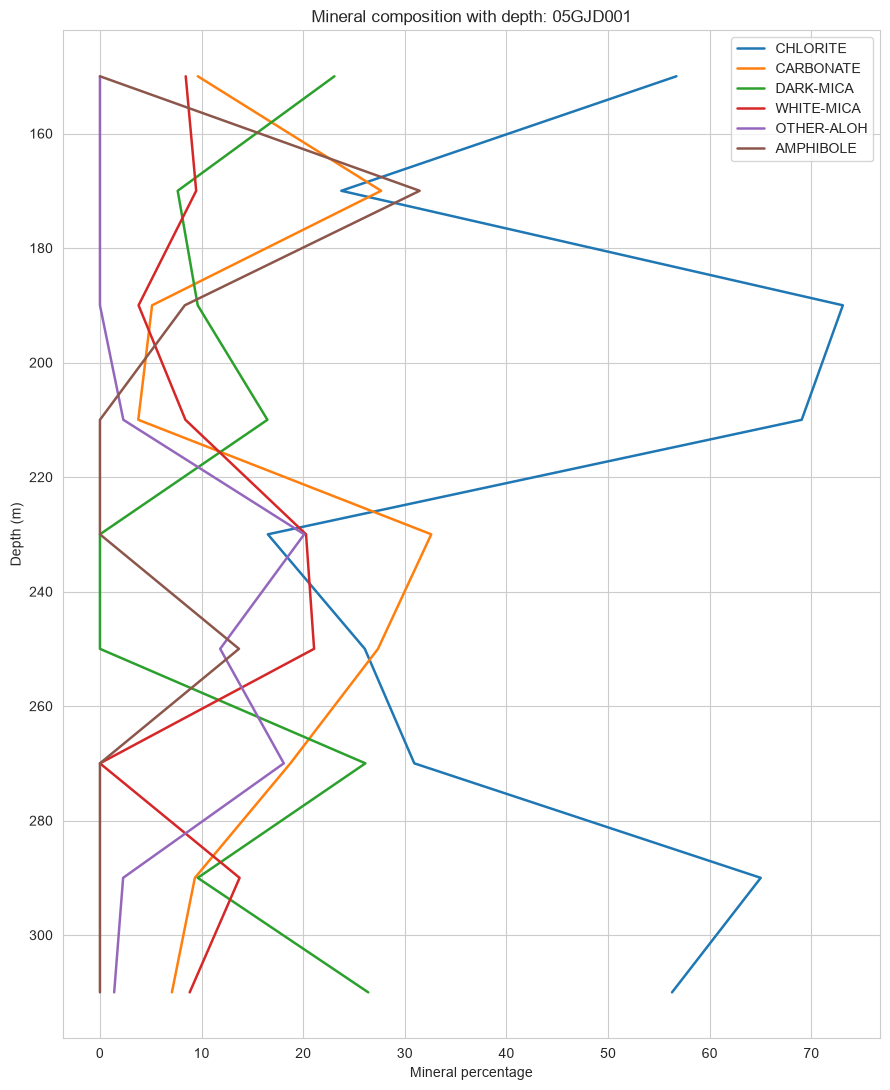

Hole analysed: 05GJD001
Top minerals: ['CHLORITE', 'CARBONATE', 'DARK-MICA', 'WHITE-MICA', 'OTHER-ALOH', 'AMPHIBOLE']


In [8]:
hole = pct["hole_id"].unique()[0]

sub = pct[pct["hole_id"] == hole].sort_values("depth")

skip = ("hole_id", "depth", "total_n")
mineral_cols = [c for c in pct.columns if c not in skip]

top = (
    sub[mineral_cols]
    .sum()
    .sort_values(ascending=False)
    .head(6)
    .index
)

fig, ax = plt.subplots(figsize=(9, 11))

for mineral in top:
    ax.plot(
        sub[mineral],
        sub["depth"],
        label=mineral,
        linewidth=1.8
    )

ax.invert_yaxis()
ax.set_xlabel("Mineral percentage")
ax.set_ylabel("Depth (m)")
ax.set_title(f"Mineral composition with depth: {hole}")
ax.legend()

plt.tight_layout()
plt.show()

print("Hole analysed:", hole)
print("Top minerals:", list(top))

Interpretation:
The mineral percentages were plotted against depth to see whether the mineral composition changes down the drill hole. The plot shows noticeable changes in minerals such as chlorite, white mica, carbonate, dark mica and amphibole at different depths. The pattern does not look completely random and suggests there is real mineralogical variation or banding with depth.

Mineral Occurrence Frequency

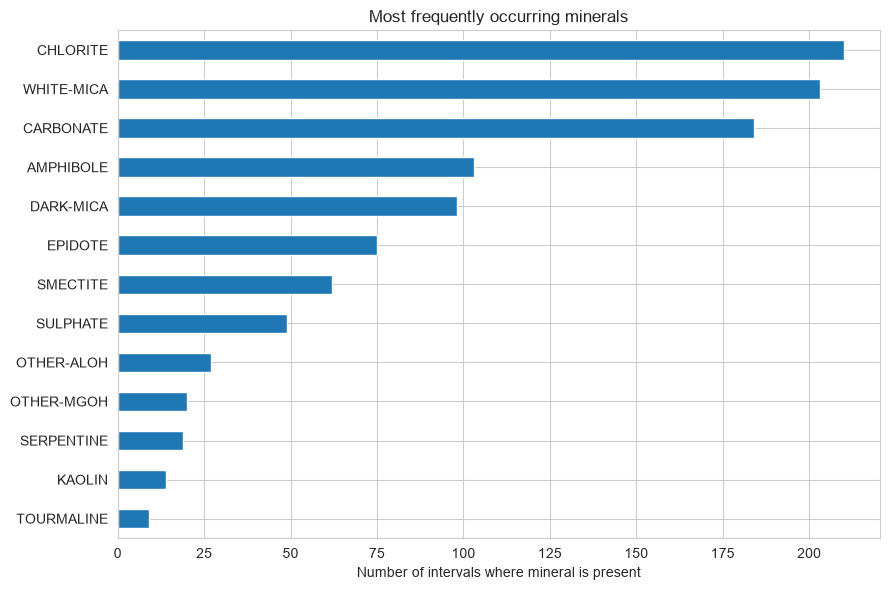

CHLORITE      210
WHITE-MICA    203
CARBONATE     184
AMPHIBOLE     103
DARK-MICA      98
EPIDOTE        75
SMECTITE       62
SULPHATE       49
OTHER-ALOH     27
OTHER-MGOH     20
SERPENTINE     19
KAOLIN         14
TOURMALINE      9
dtype: int64


In [9]:
counts = {m: (pct[m] > 0).sum() for m in mineral_cols}

s = pd.Series(counts).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
s.head(15).plot(kind="barh", ax=ax)

ax.invert_yaxis()
ax.set_xlabel("Number of intervals where mineral is present")
ax.set_title("Most frequently occurring minerals")

plt.tight_layout()
plt.show()

print(s)

Interpretation:
This analysis shows how often each mineral appears across the processed depth intervals. Chlorite and white mica are the most commonly occurring minerals, while several other minerals occur much less frequently. This helps identify which minerals are most important in the current dataset.

Classifier Mineral Availability

In [10]:
needed = ["WHITE-MICA", "CHLORITE", "HEMATITE", "KAOLIN", "GOETHITE"]

print("CLASSIFIER MINERAL CHECK")
print("=" * 50)

for mineral in needed:
    if mineral in pct.columns:
        present = (pct[mineral] > 0).sum()
        avg = pct.loc[pct[mineral] > 0, mineral].mean() if present > 0 else 0

        print(
            f"{mineral:14s}: "
            f"{present:3d}/{len(pct)} intervals "
            f"({present/len(pct)*100:5.1f}%), "
            f"avg {avg:5.1f}% when present"
        )
    else:
        print(f"{mineral:14s}: NOT IN THE DATA")

CLASSIFIER MINERAL CHECK
WHITE-MICA    : 203/276 intervals ( 73.6%), avg  43.7% when present
CHLORITE      : 210/276 intervals ( 76.1%), avg  57.3% when present
HEMATITE      : NOT IN THE DATA
KAOLIN        :  14/276 intervals (  5.1%), avg   1.4% when present
GOETHITE      : NOT IN THE DATA


Interpretation:
The five minerals used by the baseline classifier were checked against the processed dataset. WHITE-MICA appears in about 73.6% of intervals and CHLORITE in about 76.1%. KAOLIN is rare, appearing in only around 5.1% of intervals. HEMATITE and GOETHITE are completely missing from the current dataset. This is important because classifier rules that depend on those missing minerals cannot activate.

Scan Support per Depth Interval

INTERVAL SUPPORT SUMMARY
count     276.000000
mean     1794.409420
std      1085.054346
min        16.000000
25%       835.000000
50%      2072.500000
75%      2350.250000
max      5331.000000
Name: total_n, dtype: float64

Low-support intervals:
< 20 scans  : 1
< 100 scans : 5
< 500 scans : 44


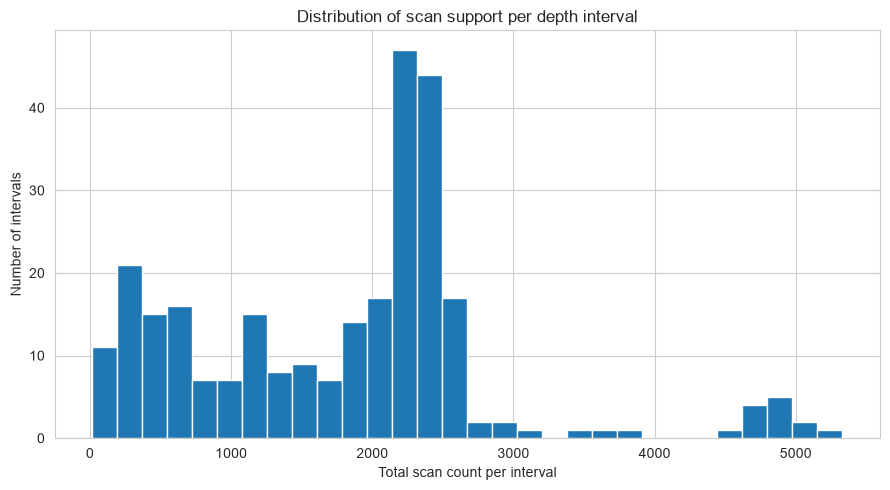

In [11]:
print("INTERVAL SUPPORT SUMMARY")
print("=" * 45)

print(pct["total_n"].describe())

print("\nLow-support intervals:")
print(f"< 20 scans  : {(pct['total_n'] < 20).sum()}")
print(f"< 100 scans : {(pct['total_n'] < 100).sum()}")
print(f"< 500 scans : {(pct['total_n'] < 500).sum()}")

fig, ax = plt.subplots(figsize=(9, 5))
pct["total_n"].hist(bins=30, ax=ax)

ax.set_xlabel("Total scan count per interval")
ax.set_ylabel("Number of intervals")
ax.set_title("Distribution of scan support per depth interval")

plt.tight_layout()
plt.show()

Interpretation:
The number of supporting scan observations varies between depth intervals. Most intervals have a reasonable amount of supporting data, but a small number have much lower scan counts. This means some intervals may be less reliable than others, so scan support should be considered when interpreting classifier or anomaly-detection results.

Dominant Mineral Distribution

In [12]:
mineral_cols = [
    c for c in pct.columns
    if c not in ["hole_id", "depth", "total_n"]
]

pct["dominant_mineral"] = pct[mineral_cols].idxmax(axis=1)
pct["dominant_pct"] = pct[mineral_cols].max(axis=1)

print("DOMINANT MINERAL SUMMARY")
print("=" * 45)

dominant_counts = pct["dominant_mineral"].value_counts()
dominant_pct = pct["dominant_mineral"].value_counts(normalize=True) * 100

summary = pd.DataFrame({
    "intervals": dominant_counts,
    "percentage": dominant_pct.round(1)
})

print(summary)

DOMINANT MINERAL SUMMARY
                  intervals  percentage
dominant_mineral                       
CHLORITE                147        53.3
WHITE-MICA               86        31.2
CARBONATE                13         4.7
AMPHIBOLE                 8         2.9
SERPENTINE                8         2.9
DARK-MICA                 7         2.5
SMECTITE                  5         1.8
EPIDOTE                   2         0.7


Interpretation:
Chlorite is the dominant mineral in about 53.3% of the analysed intervals, while white mica is dominant in about 31.2%. Together, these two minerals dominate approximately 84.5% of all intervals. This shows that the current dataset is mainly characterised by chlorite-rich and white-mica-rich zones.

Dominant Mineral Transitions with Depth

In [13]:
transition_rows = []

for hole_id, group in pct.groupby("hole_id"):
    group = group.sort_values("depth").copy()

    group["previous_mineral"] = group["dominant_mineral"].shift(1)
    group["transition"] = (
        group["dominant_mineral"] != group["previous_mineral"]
    )

    group.loc[group["previous_mineral"].isna(), "transition"] = False

    transition_rows.append(group)

transition_df = pd.concat(transition_rows, ignore_index=True)

possible = len(transition_df) - pct["hole_id"].nunique()
transitions = transition_df["transition"].sum()

print(f"Possible neighbouring transitions: {possible}")
print(f"Dominant-mineral changes: {transitions}")
print(f"Transition rate: {transitions/possible*100:.1f}%")

Possible neighbouring transitions: 256
Dominant-mineral changes: 57
Transition rate: 22.3%


Interpretation:
Adjacent depth intervals were compared to see how often the dominant mineral changes. Out of 256 possible neighbouring comparisons, 57 mineral changes were identified, giving a transition rate of 22.3%. This means the dominant mineral changes fairly regularly with depth and provides useful evidence for developing a mineral-transition detection method.

Chlorite and White-Mica Correlation

CHLORITE vs WHITE-MICA CORRELATION
Pearson correlation : -0.759
Spearman correlation: -0.674

Interpretation: Strong negative linear relationship


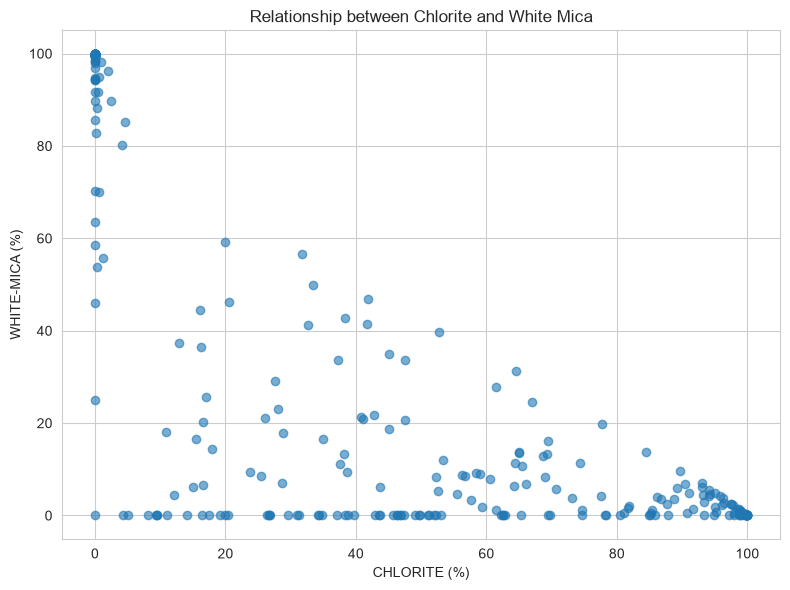

In [17]:

# Check that both mineral columns exist
if "CHLORITE" in pct.columns and "WHITE-MICA" in pct.columns:

    # Calculate correlations
    pearson = pct["CHLORITE"].corr(
        pct["WHITE-MICA"],
        method="pearson"
    )

    spearman = pct["CHLORITE"].corr(
        pct["WHITE-MICA"],
        method="spearman"
    )

    print("CHLORITE vs WHITE-MICA CORRELATION")
    print("=" * 50)
    print(f"Pearson correlation : {pearson:.3f}")
    print(f"Spearman correlation: {spearman:.3f}")

    # Simple interpretation of Pearson correlation
    if pearson <= -0.7:
        interpretation = "Strong negative linear relationship"
    elif pearson <= -0.4:
        interpretation = "Moderate negative linear relationship"
    elif pearson < -0.1:
        interpretation = "Weak negative linear relationship"
    elif pearson <= 0.1:
        interpretation = "Very weak or no linear relationship"
    elif pearson < 0.4:
        interpretation = "Weak positive linear relationship"
    elif pearson < 0.7:
        interpretation = "Moderate positive linear relationship"
    else:
        interpretation = "Strong positive linear relationship"

    print(f"\nInterpretation: {interpretation}")

    # Create scatter plot
    fig, ax = plt.subplots(figsize=(8, 6))

    ax.scatter(
        pct["CHLORITE"],
        pct["WHITE-MICA"],
        alpha=0.6
    )

    ax.set_xlabel("CHLORITE (%)")
    ax.set_ylabel("WHITE-MICA (%)")
    ax.set_title(
        "Relationship between Chlorite and White Mica"
    )

    plt.tight_layout()
    plt.show()

else:
    print("Required mineral columns are missing.")

In [18]:
pearson = pct["CHLORITE"].corr(
    pct["WHITE-MICA"],
    method="pearson"
)

spearman = pct["CHLORITE"].corr(
    pct["WHITE-MICA"],
    method="spearman"
)

print(f"Pearson correlation: {pearson:.3f}")
print(f"Spearman correlation: {spearman:.3f}")

Pearson correlation: -0.759
Spearman correlation: -0.674


Interpretation:
The relationship between chlorite and white mica was analysed using Pearson and Spearman correlation. The Pearson correlation was -0.759 and the Spearman correlation was -0.674. Both results show a clear negative relationship, meaning that intervals with high chlorite percentages generally have lower white-mica percentages, and vice versa. However, because mineral percentages form part of a total composition, this should be treated as an exploratory relationship rather than proof of a direct geological cause.

EDA Conclusion

Interpretation:
Overall, the exploratory analysis shows that the current sample is clean and contains clear changes in mineral composition with depth. Chlorite and white mica are the main minerals present, and there are regular changes in dominant mineralogy between neighbouring depth intervals. At the same time, the very high unclassified rate and the absence of some classifier minerals show that the current baseline rules need further validation. The main next step should be to discuss suitable mineral thresholds and geological interpretation with the client before relying on the classifier for ore, waste or alteration predictions.